# Spam Email Detection with Machine Learning

## Project Overview

In this project, I will build a simple **machine learning system to detect spam emails**.

The goal is to classify an email into one of two categories:

- **Spam**
- **Not Spam (Ham)**

This project is mainly a **practical exercise** to apply the fundamental concepts of **Supervised Learning** that I have been studying.

###  Machine Learning Algorithms

I will experiment with two classical classification algorithms:

- **Perceptron**
- **Logistic Regression**

The main objective is not only to obtain predictions, but also to understand how these algorithms work in a real-world classification problem.


> **Learning by building:** This project is a hands-on experiment to connect the theoretical concepts of machine learning with a practical problem.


##  Dataset Description

For this project, I will use the **Spambase dataset** from the **UCI Machine Learning Repository**.

The dataset was created for the task of **classifying emails as spam or non-spam**. It contains **4,601 email instances** and **57 features** describing different characteristics of the emails.

###  Target Variable

The target variable is `spam`:

- `0` → **Not Spam**
- `1` → **Spam**

This makes the problem a **binary classification problem**.

###  Features

The 57 features describe different properties of each email. For example:

- `word_freq_free` → percentage of words containing the word **"free"**
- `word_freq_money` → percentage of words containing the word **"money"**
- `char_freq_!` → percentage of characters that are **"!"**
- `capital_run_length_average` → average length of consecutive sequences of capital letters
- `capital_run_length_longest` → longest sequence of consecutive capital letters

In total, the dataset contains **48 word-frequency features, 6 character-frequency features, and 3 features related to sequences of capital letters**.

###  Why This Dataset?

I chose this dataset because it provides a simple and realistic way to practice **Supervised Learning and Binary Classification**.

The objective is to understand how these algorithms learn to distinguish between **spam** and **non-spam** emails.

### 📚 Source

**Dataset:** Spambase  
**Repository:** UCI Machine Learning Repository  
**Creators:** Mark Hopkins, Erik Reeber, George Forman, and Jaap Suermondt  
**Year:** 1999  
**DOI:** 10.24432/C53G6X

### link
https://archive.ics.uci.edu/dataset/94/spambase

*spambase.data :*
>  to train and evaluate your models.

*spambase.names :*
> to understand the features and target.

*spambase.documentation :* :
> to learn more about the dataset's background and construction.



```
The Spambase dataset is already transformed into numerical features, so you don't need to extract features from raw email text.
```



###  Capital Letter Features

The Spambase dataset contains **three features related to capital letters**:

#### 1. `capital_run_length_average`

The **average length** of consecutive sequences of capital letters.

**Example:**

```text
HELLO abc WORLD
```

- `HELLO` → 5 consecutive capital letters
- `WORLD` → 5 consecutive capital letters

Therefore:

$$
\text{Average} = \frac{5 + 5}{2} = 5
$$

---

#### 2. `capital_run_length_longest`

The **length of the longest** consecutive sequence of capital letters.

**Example:**

```text
HELLO abc CONGRATULATIONS
```

- `HELLO` → 5 capital letters
- `CONGRATULATIONS` → 15 capital letters

Therefore:

```text
Longest sequence = 15
```

---

#### 3. `capital_run_length_total`

The **total number of capital letters** contained in all consecutive capital-letter sequences.

**Example:**

```text
HELLO abc WORLD
```

- `HELLO` → 5 capital letters
- `WORLD` → 5 capital letters

Therefore:

```text
Total = 5 + 5 = 10
```

---

###  Summary

| Feature | Meaning |
|---|---|
| `capital_run_length_average` | Average length of capital-letter sequences |
| `capital_run_length_longest` | Length of the longest capital-letter sequence |
| `capital_run_length_total` | Total number of capital letters in these sequences |

These features can help the model identify patterns that may be associated with spam emails. However, **they do not determine by themselves whether an email is spam**. The machine learning model learns how useful these features are from the training data.

# Perceptron Algorithme

In [5]:
import numpy as np

In [6]:
class Perceptron:
    def __init__(self, learning_rate=0.01, n_iterations=4601):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        # Number of samples and features
        n_samples, n_features = X.shape #see the part "X and Y"

        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0

        # Training
        for _ in range(self.n_iterations):

            for i in range(n_samples):

                # Linear combination
                z = np.dot(X[i], self.weights) + self.bias

                # Prediction
                y_pred = 1 if z >= 0 else 0

                # Update only if prediction is wrong
                if y_pred != y[i]:
                    self.weights += self.learning_rate * (y[i] - y_pred) * X[i]
                    self.bias += self.learning_rate * (y[i] - y_pred)

        return self

    def predict(self, X):
        z = np.dot(X, self.weights) + self.bias
        return np.where(z >= 0, 1, 0)

# Now we can apply this algorithme to dataset

**upload dataset**

In [7]:
import pandas as pd

data = pd.read_csv("spambase.data", header=None)

print(data.shape)
data.head()

(4601, 58)


,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


**X and Y**

In [8]:
X = data.iloc[:, :-1]
y = data.iloc[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4601, 57)
y shape: (4601,)


**training and testing**

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (3680, 57)
Testing: (921, 57)


**Normalisation**

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) # we havn't fit here just in the training

# Perceptron training

In [17]:
perceptron = Perceptron(
    learning_rate=0.01,
    n_iterations=2000
)

perceptron.fit(X_train_scaled, y_train.values)

# Perceptron prediction

In [18]:
y_pred = perceptron.predict(X_test_scaled)

# Logistic Regression

In [ ]:
class LogisticRegression:

    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None

    # Sigmoid function
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    # Training
    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Initialize parameters
        self.weights = np.zeros(n_features)
        self.bias = 0

        # Gradient Descent
        for _ in range(self.n_iterations):

            # Linear combination
            z = np.dot(X, self.weights) + self.bias

            # Prediction as probability
            y_pred = self.sigmoid(z)

            # Calculate gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)

            # Update weights and bias
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        return self

    # Predict probabilities
    def predict_proba(self, X):

        z = np.dot(X, self.weights) + self.bias

        return self.sigmoid(z)

    # Predict classes
    def predict(self, X):

        probabilities = self.predict_proba(X)

        return np.where(probabilities > 0.5, 1, 0)

In [25]:
model = LogisticRegression(
    learning_rate=0.01,
    n_iterations=2000
)

model.fit(X_train_scaled, y_train)

In [26]:
y_pred = model.predict(X_test_scaled)

# Evaluation

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Perceptron
per_pred = perceptron.predict(X_test_scaled)

# Logistic Regression
log_pred = model.predict(X_test_scaled)

print("===== Perceptron =====")
print("Accuracy :", accuracy_score(y_test, per_pred))
print("Precision:", precision_score(y_test, per_pred))
print("Recall   :", recall_score(y_test, per_pred))
print("F1-score :", f1_score(y_test, per_pred))

print("\n===== Logistic Regression =====")
print("Accuracy :", accuracy_score(y_test, log_pred))
print("Precision:", precision_score(y_test, log_pred))
print("Recall   :", recall_score(y_test, log_pred))
print("F1-score :", f1_score(y_test, log_pred))

===== Perceptron =====
Accuracy : 0.9077090119435396
Precision: 0.8994252873563219
Recall   : 0.8622589531680441
F1-score : 0.8804500703234881

===== Logistic Regression =====
Accuracy : 0.9066232356134636
Precision: 0.9085545722713865
Recall   : 0.8484848484848485
F1-score : 0.8774928774928775


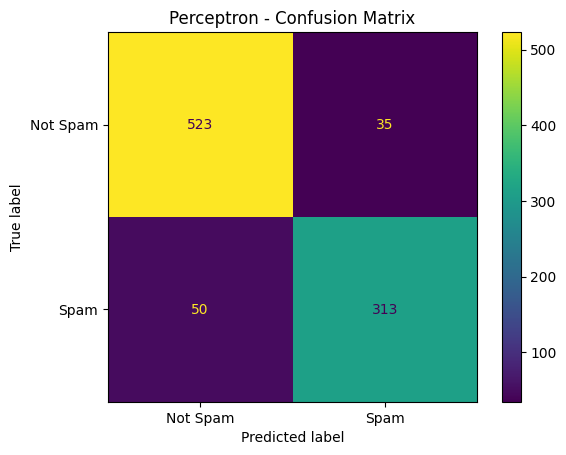

In [29]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    per_pred,
    display_labels=["Not Spam", "Spam"]
)

plt.title("Perceptron - Confusion Matrix")
plt.show()

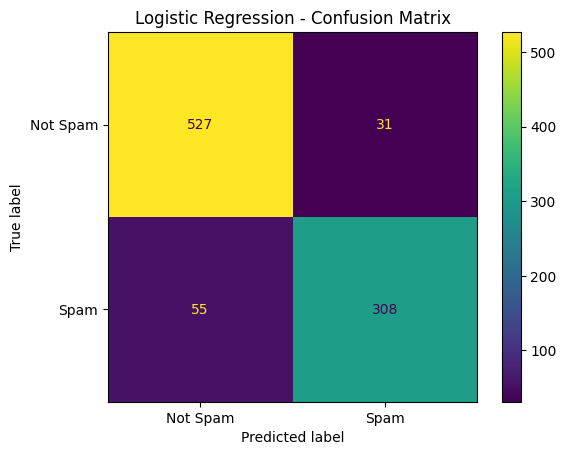

In [30]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_pred,
    display_labels=["Not Spam", "Spam"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

## Perceptron vs. Logistic Regression: Results Analysis

### 1. Confusion Matrix Results

We evaluated both models on the same test dataset to compare their performance in spam email classification.

| Metric | Perceptron | Logistic Regression |
|---|---:|---:|
| True Negatives (TN) | 532 | 527 |
| False Positives (FP) | 53 | 31 |
| False Negatives (FN) | 50 | 55 |
| True Positives (TP) | 313 | 308 |
| Accuracy | 90.77% | 90.66% |
| Spam Recall | 86.23% | 84.86% |

**Note:** Class `0` represents legitimate emails (not spam), while class `1` represents spam emails.

### 2. Understanding the Results

**Perceptron**

- Achieved an accuracy of **90.77%**, slightly higher than Logistic Regression.
- Correctly detected 313 spam emails.
- Missed 50 spam emails (False Negatives).
- Incorrectly classified 53 legitimate emails as spam (False Positives).

**Logistic Regression**

- Achieved an accuracy of **90.66%**, very close to the Perceptron's accuracy.
- Correctly detected 308 spam emails.
- Missed 55 spam emails (False Negatives).
- Incorrectly classified only 31 legitimate emails as spam (False Positives).

### 3. Comparing the Models

The difference in accuracy is very small: only **0.11 percentage points**.

However, the models make different types of mistakes:

- **Perceptron** detects five more spam emails and produces five fewer False Negatives.
- **Logistic Regression** produces 22 fewer False Positives, reducing the risk of legitimate emails being incorrectly classified as spam.

Since the main objective of this project is to detect spam emails, the Perceptron performs slightly better in terms of spam detection on this test set.

### 4. Conclusion

Based on these results, **the Perceptron is the preferred model if minimizing missed spam emails is the main priority**. Logistic Regression may be preferable when avoiding the misclassification of legitimate emails is more important.

Neither model is universally better. The final choice depends on the relative cost of False Positives and False Negatives.

In [31]:
import joblib

joblib.dump(model, "logistic_regression.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']